# PyTorch — L’essentiel du framework

**Objectifs :**
- comprendre les `Tensor` ;
- utiliser `Autograd` ;
- construire un modèle avec `nn.Module` ;
- définir un `Loss` et un `Optimizer` ;
- écrire une boucle d’apprentissage ;
- distinguer `train()` et `eval()` ;
- utiliser `Dataset` / `DataLoader` ;
- entraîner un exemple de régression et un exemple de classification ;
- sauvegarder et recharger un modèle.

## 0. Préparation

Le notebook fonctionne sur CPU. S’il existe un GPU CUDA, PyTorch pourra l’utiliser automatiquement.

### Installation de l'environnement

Exécutez la cellule suivante une seule fois (le `-q` limite l'affichage), puis redémarrez le noyau si de nouveaux paquets ont été installés. Les paquets déjà présents ne sont pas réinstallés.

- Les données MNIST sont téléchargées automatiquement dans `./data` (environ 11 Mo, connexion internet nécessaire la première fois).
- `torchviz` (cellule 5 du cours) demande aussi le programme **Graphviz** installé sur le système (`sudo apt install graphviz`, `brew install graphviz`, ou l'installeur Windows).

In [1]:
%pip install -q torch torchvision torcheval torchmetrics torchviz scikit-learn matplotlib numpy

Note: you may need to restart the kernel to use updated packages.


c:\Users\Asus\OneDrive - Ecole Marocaine des Sciences de l'Ingénieur\lab_pytorch_v1\.venv\Scripts\python.exe: No module named pip


In [2]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())

PyTorch version: 2.14.1+cpu
CUDA disponible: False


## 1. Workflow général

Le cycle de base est :

**Données → Tensors → Modèle → Prédictions → Loss → Backward → Optimizer → Mise à jour**

In [3]:
# Pseudo-code de la logique générale
# y_pred = model(X)
# loss = criterion(y_pred, y)
# optimizer.zero_grad()
# loss.backward()
# optimizer.step()

## 2. Les Tensors

Un `Tensor` est la structure de données fondamentale de PyTorch.

In [4]:
scalar = torch.tensor(3.0)
vector = torch.tensor([1.0, 2.0, 3.0])
matrix = torch.tensor([[1.0, 2.0], [3.0, 4.0]])

print("scalar:", scalar, "shape =", scalar.shape)
print("vector:", vector, "shape =", vector.shape)
print("matrix:", matrix, "shape =", matrix.shape)
print("dtype:", matrix.dtype)
print("ndim:", matrix.ndim)

scalar: tensor(3.) shape = torch.Size([])
vector: tensor([1., 2., 3.]) shape = torch.Size([3])
matrix: tensor([[1., 2.],
        [3., 4.]]) shape = torch.Size([2, 2])
dtype: torch.float32
ndim: 2


### Manipulation de Tensors

In [5]:
x = torch.arange(12)
print("x =", x)

x2 = x.reshape(3, 4)
print("reshape(3,4):", x2)

print("Colonne 1:", x2[:, 1])
print("Ligne 0:", x2[0, :])

A = torch.tensor([[1., 2.], [3., 4.]])
B = torch.tensor([[2., 0.], [1., 2.]])
print("A @ B =", A @ B)

print("mean(A) =", A.mean())
print("sum(A) =", A.sum())

x = tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])
reshape(3,4): tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
Colonne 1: tensor([1, 5, 9])
Ligne 0: tensor([0, 1, 2, 3])
A @ B = tensor([[ 4.,  4.],
        [10.,  8.]])
mean(A) = tensor(2.5000)
sum(A) = tensor(10.)


## 3. CPU, GPU et `device`

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device utilisé:", device)

x = torch.tensor([1.0, 2.0, 3.0]).to(device)
print("x.device =", x.device)

Device utilisé: cpu
x.device = cpu


## 4. Autograd

`Autograd` calcule automatiquement les dérivées à partir du graphe de calcul.

In [7]:
x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

y = w * x + b
loss = (y - 10) ** 2

loss.backward()

print("y =", y.item())
print("loss =", loss.item())
print("dLoss/dw =", w.grad.item())
print("dLoss/db =", b.grad.item())

y = 7.0
loss = 9.0
dLoss/dw = -12.0
dLoss/db = -6.0


In [8]:
import torch

x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

y = w * x + b
loss = (y - 10) ** 2

dw, db = torch.autograd.grad(loss, (w, b))

print("y =", y.item())
print("loss =", loss.item())
print("dLoss/dw =", dw.item())
print("dLoss/db =", db.item())

y = 7.0
loss = 9.0
dLoss/dw = -12.0
dLoss/db = -6.0


### Vérification analytique

Ici :

\[
y = wx+b
\]

et

\[
L=(y-10)^2
\]

Donc :

\[

rac{\partial L}{\partial w}=2(y-10)x
\]

\[

rac{\partial L}{\partial b}=2(y-10)
\]

In [9]:
y_val = (3.0 * 2.0 + 1.0)
dL_dw = 2 * (y_val - 10) * 2.0
dL_db = 2 * (y_val - 10)
print(dL_dw, dL_db)

-12.0 -6.0


## 5. Un neurone avec `nn.Linear`

Un neurone linéaire calcule essentiellement :

\[
z = \sum_i w_i x_i + b
\]

In [10]:
model = nn.Linear(3, 1)
x = torch.tensor([[1.0, 2.0, 3.0]])
y = model(x)

print("Sortie:", y)
print("Poids:", model.weight)
print("Biais:", model.bias)

Sortie: tensor([[0.0924]], grad_fn=<AddmmBackward0>)
Poids: Parameter containing:
tensor([[-0.0893, -0.2365,  0.0347]], requires_grad=True)
Biais: Parameter containing:
tensor([0.5507], requires_grad=True)


In [64]:
import torch
import torch.nn as nn
from torchviz import make_dot

model = nn.Linear(3, 1)
x = torch.tensor([[1.0, 2.0, 3.0]])
y = model(x)

print("Sortie:", y)
print("Poids:", model.weight)
print("Biais:", model.bias)

dot = make_dot(y, params=dict(model.named_parameters()))
dot.render("graphe_operations", format="png", cleanup=True)

Sortie: tensor([[0.7685]], grad_fn=<AddmmBackward0>)
Poids: Parameter containing:
tensor([[0.1606, 0.3910, 0.0369]], requires_grad=True)
Biais: Parameter containing:
tensor([-0.2848], requires_grad=True)


ExecutableNotFound: failed to execute WindowsPath('dot'), make sure the Graphviz executables are on your systems' PATH

## 6. Construire un réseau avec `nn.Module`

In [12]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 3)
        )

    def forward(self, x):
        return self.net(x)

model = MLP()
print(model)

MLP(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=3, bias=True)
  )
)


In [13]:
model = nn.Sequential(
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 3)
        )
print(model)

Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=3, bias=True)
)


## 7. Fonctions d’activation

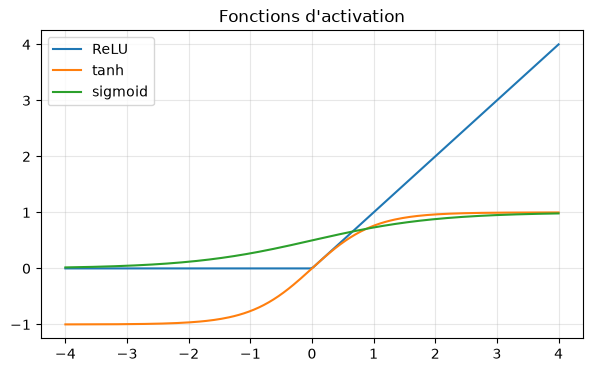

In [14]:
x = torch.linspace(-4, 4, 200)
relu = torch.relu(x)
tanh = torch.tanh(x)
sigmoid = torch.sigmoid(x)

plt.figure(figsize=(7,4))
plt.plot(x.numpy(), relu.numpy(), label='ReLU')
plt.plot(x.numpy(), tanh.numpy(), label='tanh')
plt.plot(x.numpy(), sigmoid.numpy(), label='sigmoid')
plt.grid(True, alpha=0.3)
plt.legend()
plt.title("Fonctions d'activation")
plt.show()

## 8. Forward propagation

L’appel `model(X)` déclenche automatiquement `model.forward(X)`.

In [15]:
X = torch.randn(5, 4)
predicted = model(X)
print("Shape entrée :", X.shape)
print("Shape sortie :", predicted.shape)

Shape entrée : torch.Size([5, 4])
Shape sortie : torch.Size([5, 3])


## 9. Fonctions de coût

Cas principaux :
- régression : `nn.MSELoss()` ;
- classification multi-classe : `nn.CrossEntropyLoss()` ;
- classification binaire : `nn.BCEWithLogitsLoss()`.

In [16]:
# Régression
criterion_reg = nn.MSELoss()
y_pred = torch.tensor([[2.0], [4.0]])
y_true = torch.tensor([[3.0], [5.0]])
print("MSE =", criterion_reg(y_pred, y_true).item())

# Classification multi-classe
criterion_cls = nn.CrossEntropyLoss()
pred = torch.tensor([[2.0, 1.0, 0.5], [0.2, 0.1, 2.0]])
y = torch.tensor([0, 2])
print("CrossEntropy =", criterion_cls(pred, y).item())

MSE = 1.0
CrossEntropy = 0.36905235052108765


## 10. Optimizers

L’optimiseur utilise les gradients pour mettre à jour les paramètres.

In [17]:
simple_model = nn.Linear(1, 1)
optimizer = torch.optim.Adam(simple_model.parameters(), lr=1e-2)
print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    weight_decay: 0
)


## 11. La boucle d’apprentissage

C’est le cœur de PyTorch.

In [18]:
X = torch.randn(8, 1)
y = 2 * X + 1
simple_model = nn.Linear(1, 1)
optimizer = torch.optim.Adam(simple_model.parameters(), lr=1e-2)
criterion = nn.MSELoss()
epochs = 500
# Exemple générique
for epoch in range(epochs):
    simple_model.train()
    y_pred = simple_model(X)
    loss = criterion(y_pred, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if epoch % 100 ==0 : 
        print(f"epoch={epoch} loss={loss.item():.4f}")

epoch=0 loss=9.9952
epoch=100 loss=3.6496
epoch=200 loss=1.0807
epoch=300 loss=0.2864
epoch=400 loss=0.0789


## 12. `train()` vs `eval()`

`model.train()` et `model.eval()` influencent notamment le comportement de `Dropout` et `BatchNorm`.

`eval()` ne désactive pas le calcul des gradients. Pour l’inférence, on utilise généralement `torch.inference_mode()`.

In [19]:
class DropoutDemo(nn.Module):
    def __init__(self):
        super().__init__()
        self.dropout = nn.Dropout(p=0.5)

    def forward(self, x):
        return self.dropout(x)

m = DropoutDemo()
x = torch.ones(10)

m.train()
print("train() :", m(x))

m.eval()
with torch.inference_mode():
    print("eval()  :", m(x))

train() : tensor([0., 0., 2., 2., 2., 2., 0., 0., 2., 2.])
eval()  : tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


## 13. Dataset et DataLoader

In [20]:
X = torch.randn(100, 3)
y = torch.randn(100, 1)

dataset = TensorDataset(X, y)
loader = DataLoader(dataset, batch_size=16, shuffle=True)

for X_batch, y_batch in loader:
    print("Batch X:", X_batch.shape, "Batch y:", y_batch.shape)
    break

Batch X: torch.Size([16, 3]) Batch y: torch.Size([16, 1])


# Partie pratique 1 — Régression linéaire

Nous générons des données proches de :

\[
y = 3x + 2 + bruit
\]

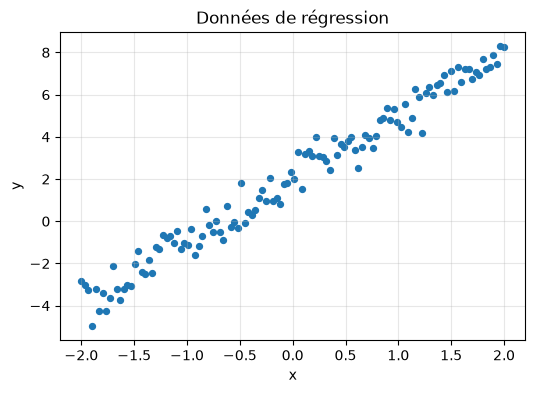

In [21]:
torch.manual_seed(42)

X = torch.linspace(-2, 2, 120).unsqueeze(1)
noise = 0.6 * torch.randn_like(X)
y = 3 * X + 2 + noise

plt.figure(figsize=(6,4))
plt.scatter(X.numpy(), y.numpy(), s=18)
plt.title("Données de régression")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, alpha=0.3)
plt.show()

## 14. Modèle, loss et optimizer

In [22]:
model_reg = nn.Linear(1, 1)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model_reg.parameters(), lr=0.05)

## 15. Entraînement de la régression

In [23]:
losses = []

for epoch in range(300):
    model_reg.train()

    y_pred = model_reg(X)
    loss = criterion(y_pred, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

print("Dernier loss:", losses[-1])
print("w appris:", model_reg.weight.item())
print("b appris:", model_reg.bias.item())

Dernier loss: 0.3438417613506317
w appris: 2.9894580841064453
b appris: 2.030014991760254


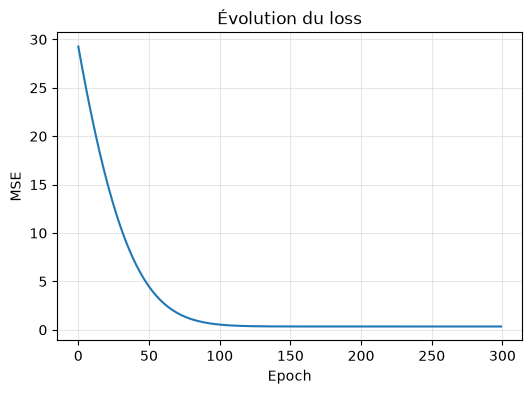

In [24]:
plt.figure(figsize=(6,4))
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Évolution du loss")
plt.grid(True, alpha=0.3)
plt.show()

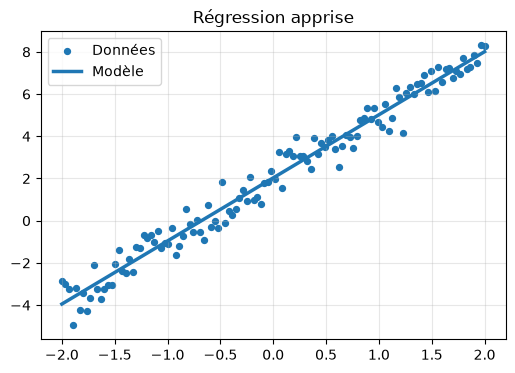

In [25]:
model_reg.eval()
with torch.inference_mode():
    y_hat = model_reg(X)

plt.figure(figsize=(6,4))
plt.scatter(X.numpy(), y.numpy(), s=18, label="Données")
plt.plot(X.numpy(), y_hat.numpy(), linewidth=2.5, label="Modèle")
plt.legend()
plt.title("Régression apprise")
plt.grid(True, alpha=0.3)
plt.show()

In [27]:
from torcheval.metrics import R2Score
metric = R2Score()
metric.update(y_hat,y)
r2=metric.compute()
print(f"R2 Score = {r2:.3f}")

c:\Users\Asus\OneDrive - Ecole Marocaine des Sciences de l'Ingénieur\lab_pytorch_v1\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


R2 Score = 0.972


# Partie pratique 2 — Classification

Créons deux classes de points en 2D.

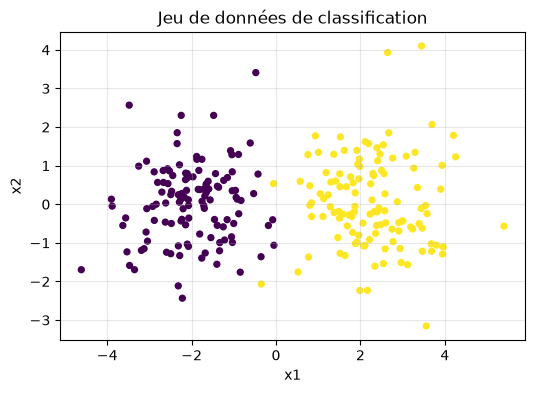

In [28]:
torch.manual_seed(0)

n = 120
class0 = torch.randn(n, 2) + torch.tensor([-2.0, 0.0])
class1 = torch.randn(n, 2) + torch.tensor([ 2.0, 0.0])

X_cls = torch.cat([class0, class1], dim=0)
y_cls = torch.cat([
    torch.zeros(n, dtype=torch.long),
    torch.ones(n, dtype=torch.long)
])

plt.figure(figsize=(6,4))
plt.scatter(X_cls[:,0], X_cls[:,1], c=y_cls, s=18)
plt.title("Jeu de données de classification")
plt.xlabel("x1")
plt.ylabel("x2")
plt.grid(True, alpha=0.3)
plt.show()

## 16. Modèle de classification

In [29]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 2)
        )

    def forward(self, x):
        return self.net(x)

model_cls = Classifier()
criterion_cls = nn.CrossEntropyLoss()
optimizer_cls = torch.optim.Adam(model_cls.parameters(), lr=0.01)

## 17. Entraînement de la classification

In [30]:
losses_cls = []

for epoch in range(250):
    model_cls.train()

    logits = model_cls(X_cls)
    loss = criterion_cls(logits, y_cls)

    optimizer_cls.zero_grad()
    loss.backward()
    optimizer_cls.step()

    losses_cls.append(loss.item())

print("Dernier loss:", losses_cls[-1])

Dernier loss: 0.0006943687913008034


In [31]:
model_cls.eval()
with torch.inference_mode():
    logits = model_cls(X_cls)
    pred = logits.argmax(dim=1)
    accuracy = (pred == y_cls).float().mean()

print(f"Accuracy = {accuracy.item()*100:.2f}%")

Accuracy = 100.00%


Accuracy = 1.0000, recall= 1.0000, precision=1.0000, f1score=1.0000
tensor([[120,   0],
        [  0, 120]])


(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='Predicted class', ylabel='True class'>)

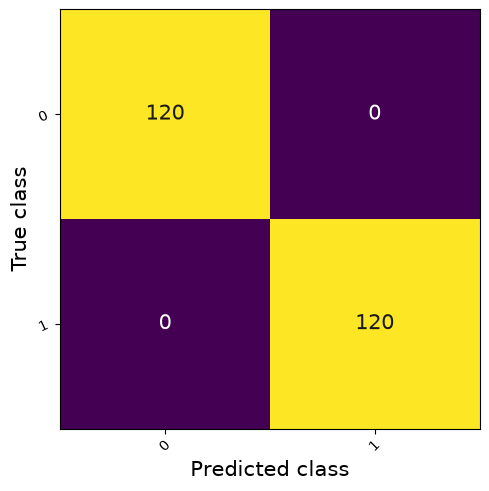

In [32]:
from torcheval.metrics import BinaryAccuracy, BinaryRecall, BinaryPrecision, BinaryPrecision, BinaryF1Score
from torchmetrics.classification import MulticlassConfusionMatrix, BinaryConfusionMatrix
accuracy_metric = BinaryAccuracy()
accuracy_metric.update(y_cls,pred)
accuracy_value = accuracy_metric.compute()

recall_metric = BinaryRecall()
recall_metric.update(y_cls, pred)
recall_value = recall_metric.compute()

precision_metric = BinaryPrecision()
precision_metric.update(y_cls,pred)
precision_value = precision_metric.compute()

f1_score_metric = BinaryF1Score()
f1_score_metric.update(y_cls, pred)
f1_score_value = f1_score_metric.compute()
print(f"Accuracy = {accuracy_value:.4f}, recall= {recall_value:.4f}, precision={precision_value:.4f}, f1score={f1_score_value:.4f}")

metric = BinaryConfusionMatrix()
confusion_matrix = metric(pred, y_cls)
print(confusion_matrix)
metric.plot()

## Visualisation de la frontière de décision

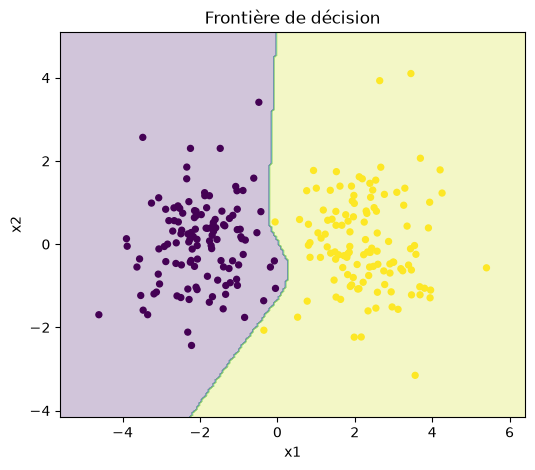

In [33]:
x1_min, x1_max = X_cls[:,0].min()-1, X_cls[:,0].max()+1
x2_min, x2_max = X_cls[:,1].min()-1, X_cls[:,1].max()+1

xx1, xx2 = torch.meshgrid(
    torch.linspace(x1_min, x1_max, 200),
    torch.linspace(x2_min, x2_max, 200),
    indexing='ij'
)

grid = torch.stack([xx1.reshape(-1), xx2.reshape(-1)], dim=1)

model_cls.eval()
with torch.inference_mode():
    zz = model_cls(grid).argmax(dim=1).reshape(xx1.shape)

plt.figure(figsize=(6,5))
plt.contourf(xx1.numpy(), xx2.numpy(), zz.numpy(), alpha=0.25)
plt.scatter(X_cls[:,0], X_cls[:,1], c=y_cls, s=18)
plt.title("Frontière de décision")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()

## 18. Sauvegarder et recharger un modèle

In [34]:
path = "classifier_state_dict.pt"
torch.save(model_cls.state_dict(), path)
print("Modèle sauvegardé dans", path)

new_model = Classifier()
new_model.load_state_dict(torch.load(path, weights_only=True))
new_model.eval()

with torch.inference_mode():
    pred_new = new_model(X_cls).argmax(dim=1)

print("Prédictions identiques:", torch.equal(pred, pred_new))

Modèle sauvegardé dans classifier_state_dict.pt
Prédictions identiques: True


# Synthèse

Les briques essentielles de PyTorch sont maintenant en place :

1. `Tensor`
2. `nn.Module`
3. `forward()`
4. fonction de coût
5. `optimizer.zero_grad()`
6. `loss.backward()`
7. `optimizer.step()`
8. `train()` / `eval()`
9. `Dataset` / `DataLoader`
10. sauvegarde avec `state_dict()`

Cette mécanique reste pratiquement la même pour des modèles plus avancés : CNN, Transformers, modèles génératifs ou PINNs.

# Exercices

### Exercice 1 : Régression

Prédire le salaire selon l’ancienneté et le niveau d’expertise

Objectif:

Construire un modèle de régression linéaire multiple pour prédire le salaire mensuel à partir de deux variables :
- Ancienneté : nombre d’années d’expérience.
- Niveau d’expertise : note de 1 à 5.
Le modèle doit apprendre la relation :

Salaire = w_1 * Ancienneté + w_2 * Expertise + b 

Les salaires sont exprimés en dirhams (DH). Les données sont fictives et servent uniquement à l’apprentissage.

1. *Générer les données*

Pour cet exercice, on suppose que les salaires suivent approximativement la règle : Salaire = 4000 + 600 * Ancienneté + 1500 * Expertise} + Bruit
Le bruit représente les variations individuelles non expliquées par les deux variables.

In [35]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

n = 300

anciennete = torch.randint(0, 21, (n, 1)).float()

expertise = torch.randint(1, 6, (n, 1)).float()

bruit = torch.randn(n, 1) * 500

salaires = (
    4000
    + 600 * anciennete
    + 1500 * expertise
    + bruit
)

X = torch.cat([anciennete, expertise], dim=1)


y = salaires

for i in range(5):
    print(
        f"Ancienneté : {X[i, 0].item():.0f} ans | "
        f"Expertise : {X[i, 1].item():.0f}/5 | "
        f"Salaire : {y[i, 0].item():.2f} DH"
    )

Ancienneté : 15 ans | Expertise : 2/5 | Salaire : 16262.90 DH
Ancienneté : 2 ans | Expertise : 3/5 | Salaire : 10541.39 DH
Ancienneté : 4 ans | Expertise : 3/5 | Salaire : 10948.37 DH
Ancienneté : 19 ans | Expertise : 3/5 | Salaire : 20028.54 DH
Ancienneté : 18 ans | Expertise : 2/5 | Salaire : 18036.38 DH


**Travail demandé**

- Affichez les dimensions de X et de y.
- Calculez le salaire moyen.
- Tracez un nuage de points représentant le salaire selon l’ancienneté, avec une couleur différente selon l’expertise.


Dimensions de X : (300, 2)
Dimensions de y : (300, 1)
Salaire moyen : 15010.55 DH


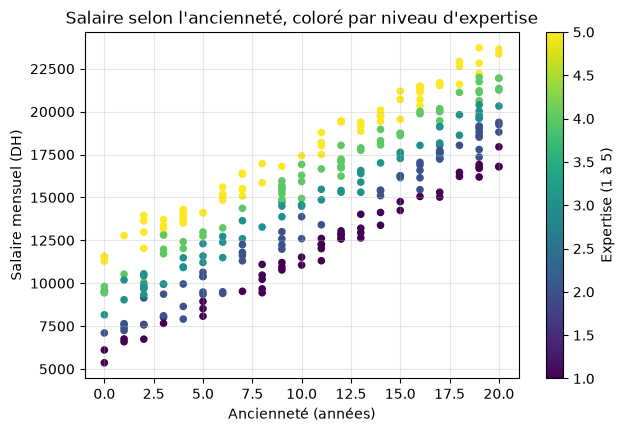

In [36]:
print("Dimensions de X :", tuple(X.shape))   
print("Dimensions de y :", tuple(y.shape))   
print(f"Salaire moyen : {y.mean().item():.2f} DH")  

plt.figure(figsize=(7, 4.5))
sc = plt.scatter(X[:, 0].numpy(), y[:, 0].numpy(), c=X[:, 1].numpy(), cmap="viridis", s=20)
plt.colorbar(sc, label="Expertise (1 à 5)")
plt.xlabel("Ancienneté (années)")
plt.ylabel("Salaire mensuel (DH)")
plt.title("Salaire selon l'ancienneté, coloré par niveau d'expertise")
plt.grid(alpha=0.3)
plt.show()

2. *Séparer et préparer les données*
Utilisez 80 % des données pour l’entraînement et 20 % pour le test.

Pour faciliter l’apprentissage :

standardisez les entrées à partir des statistiques du jeu d’entraînement ;
exprimez les salaires en milliers de DH.

In [ ]:
indices = torch.randperm(n)
limite = int(0.8 * n)

train_indices = indices[:limite]
test_indices = indices[limite:]

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices] / 1000
y_test = y[test_indices] / 1000


moyenne = X_train.mean(dim=0, keepdim=True)
ecart_type = X_train.std(dim=0, keepdim=True)

X_train_norm = (X_train - moyenne) / ecart_type
X_test_norm = (X_test - moyenne) / ecart_type

3. *Construire et entraîner le modèle*

In [38]:
#
model = nn.Linear(2, 1)


criterion = nn.MSELoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.05
)

historique = []

model.train()

for epoch in range(500):
    
    optimizer.zero_grad()

    
    predictions = model(X_train_norm)

   
    loss = criterion(predictions, y_train)

   
    loss.backward()

    
    optimizer.step()

    historique.append(loss.item())

    if (epoch + 1) % 100 == 0:
        print(
            f"Époque {epoch + 1} | "
            f"Perte : {loss.item():.4f}"
        )

Époque 100 | Perte : 0.2391
Époque 200 | Perte : 0.2391
Époque 300 | Perte : 0.2391
Époque 400 | Perte : 0.2391
Époque 500 | Perte : 0.2391


Travail demandé :

- Complétez le modèle et la boucle d’entraînement.
- Tracez l’évolution de la perte :


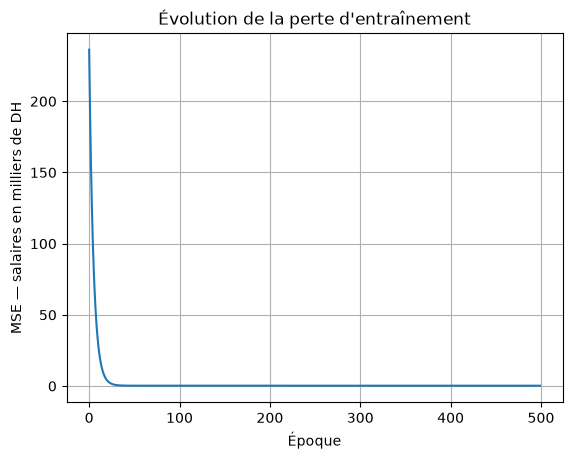

In [39]:
plt.plot(historique)
plt.xlabel("Époque")
plt.ylabel("MSE — salaires en milliers de DH")
plt.title("Évolution de la perte d'entraînement")
plt.grid()
plt.show()

4. Évaluer les prédictions

In [40]:
model.eval()

with torch.no_grad():
    predictions_test = model(X_test_norm)

  
    predictions_dh = predictions_test * 1000
    salaires_reels_dh = y_test * 1000

    
    mae = torch.abs(predictions_dh - salaires_reels_dh).mean()

print(f"Erreur absolue moyenne : {mae.item():.2f} DH")

Erreur absolue moyenne : 381.64 DH


Interprétation : une MAE de 400 DH signifie que les prédictions s’écartent, en moyenne, de 400 DH des salaires réels.

5. Prédire le salaire d’un nouveau salarié

Prédisez le salaire d’une personne ayant :

- 7 ans d’ancienneté ;
- un niveau d’expertise de 4/5.

In [41]:
nouveau_salarie = torch.tensor([[7.0, 4.0]])


nouveau_salarie_norm = (nouveau_salarie - moyenne) / ecart_type

with torch.no_grad():
    salaire_predit = model(nouveau_salarie_norm) * 1000  

print(f"Salaire estimé : {salaire_predit.item():.2f} DH")

Salaire estimé : 14201.94 DH


Vérification : d’après la règle de génération, le salaire sans bruit est :

4000 + 600 * 7 + 1500 * 4 = 14200 DH

Votre prédiction devrait être proche de cette valeur.

Questions complémentaires :

- À expertise constante, quel est l’effet d’une année d’ancienneté supplémentaire ?
- Pourquoi la perte ne devient-elle pas exactement nulle ?
- Le modèle est-il fiable pour une ancienneté de 40 ans, absente des données d’entraînement ?
- Quel effet aurait une augmentation du bruit sur la précision ?
- Retrouvez les coefficients en unités d’origine à partir des paramètres du modèle entraîné. Ils devraient être proches de 600, 1500 et 4000.

Remarque : traiter l’expertise comme une note numérique suppose que chaque passage d’un niveau au suivant a le même effet sur le salaire. Cette hypothèse simplifie l’exercice, mais doit être vérifiée avec des données réelles.

In [42]:
w = model.weight.detach()   
b = model.bias.detach()     

w_orig = (w / ecart_type) * 1000
b_orig = (b - (w * moyenne / ecart_type).sum()) * 1000

print(f"Effet d'une année d'ancienneté : {w_orig[0, 0].item():8.1f} DH   (valeur vraie : 600)")
print(f"Effet d'un niveau d'expertise  : {w_orig[0, 1].item():8.1f} DH   (valeur vraie : 1500)")
print(f"Salaire de base (biais)        : {b_orig.item():8.1f} DH   (valeur vraie : 4000)")

Effet d'une année d'ancienneté :    592.7 DH   (valeur vraie : 600)
Effet d'un niveau d'expertise  :   1490.7 DH   (valeur vraie : 1500)
Salaire de base (biais)        :   4090.3 DH   (valeur vraie : 4000)


#### Réponses — Exercice 1

**À expertise constante, quel est l'effet d'une année d'ancienneté supplémentaire ?**
Le modèle est linéaire : une année de plus augmente le salaire prédit d'un montant constant, égal au coefficient de l'ancienneté en unités d'origine, soit environ **+600 DH par mois** (la valeur vraie de la règle de génération), quel que soit le niveau d'expertise.

**Pourquoi la perte ne devient-elle pas exactement nulle ?**
Les salaires contiennent un bruit aléatoire (écart-type de 500 DH) que ni l'ancienneté ni l'expertise ne peuvent expliquer. C'est l'erreur irréductible : même le modèle parfait `4000 + 600 × ancienneté + 1500 × expertise` ferait en moyenne une erreur quadratique égale à la variance du bruit, soit 500² = 250 000 DH², c'est-à-dire **environ 0,25** dans l'unité de la perte (milliers de DH au carré). De même, la MAE attendue vaut environ 0,8 × 500 ≈ 400 DH, ce qui correspond à l'exemple d'interprétation donné plus haut.

**Le modèle est-il fiable pour une ancienneté de 40 ans ?**
Non. Les données d'entraînement couvrent 0 à 20 ans : prédire à 40 ans est une **extrapolation**. Le modèle prolonge simplement la droite apprise (il prédirait plus de 30 000 DH), mais rien ne garantit que la relation reste linéaire hors de la plage observée (plafonnement des échelles salariales, fin de carrière, etc.). Un réseau n'est fiable que dans le domaine couvert par ses données d'entraînement.

**Quel effet aurait une augmentation du bruit sur la précision ?**
L'erreur irréductible augmenterait : la perte et la MAE finales seraient plus grandes (elles croissent avec l'écart-type du bruit) et le R² diminuerait. Les coefficients appris seraient aussi estimés avec moins de précision (ils varieraient davantage d'un échantillon à l'autre), tout en restant en moyenne proches de 600, 1500 et 4000 si le bruit est centré. Ce n'est pas un défaut de l'entraînement : le bruit fixe une limite que le modèle ne peut pas dépasser.

**Coefficients en unités d'origine.**
Si `y_k = Σ wᵢ (xᵢ − μᵢ)/σᵢ + b` (en milliers de DH), alors en DH : `wᵢ_orig = 1000 · wᵢ/σᵢ` et `b_orig = 1000 · (b − Σ wᵢ μᵢ/σᵢ)`. C'est ce que calcule la cellule ci-dessus ; les valeurs obtenues doivent être proches de 600, 1500 et 4000.

**Remarque sur l'expertise.** Traiter la note comme une variable numérique impose que chaque passage au niveau supérieur ait le même effet (+1500 DH). Sur des données réelles, on vérifierait cette hypothèse, par exemple en encodant l'expertise en variables indicatrices (une colonne par niveau) et en comparant les erreurs.

**1. Préparation des données**

In [43]:
import torch
from torch import nn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)

#
iris = load_iris()
X, y = iris.data, iris.target


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Dimensions :", X_train.shape, y_train.shape)

Dimensions : torch.Size([120, 4]) torch.Size([120])


**Questions :**

- Que représentent les quatre colonnes de X_train ?
- Pourquoi utilise-t-on torch.long pour les étiquettes ?
- Pourquoi ne faut-il pas ajuster le StandardScaler sur les données de test ?

#### Réponses — Iris

**Que représentent les quatre colonnes de `X_train` ?**
La longueur du sépale, la largeur du sépale, la longueur du pétale et la largeur du pétale (en cm, dans cet ordre, cf. `iris.feature_names`). Après `StandardScaler`, chaque colonne a une moyenne proche de 0 et un écart-type proche de 1 sur le jeu d'entraînement.

**Pourquoi utilise-t-on `torch.long` pour les étiquettes ?**
`nn.CrossEntropyLoss` attend, pour chaque exemple, l'**indice de la classe correcte** (0, 1 ou 2), sous forme d'entier 64 bits (`torch.long`). Ce ne sont pas des valeurs continues : des étiquettes flottantes seraient interprétées comme des probabilités et provoqueraient une erreur.

**Pourquoi ne faut-il pas ajuster le `StandardScaler` sur les données de test ?**
Le jeu de test simule des données jamais vues. Calculer la moyenne et l'écart-type avec le test ferait fuiter de l'information du test vers le prétraitement (*data leakage*) et donnerait une évaluation trop optimiste. On ajuste donc le scaler sur l'entraînement uniquement (`fit_transform`), puis on applique les mêmes statistiques au test (`transform`).

**2. Construire le réseau**

In [ ]:
model = nn.Sequential(
    nn.Linear(4, 16),  
    nn.ReLU(),
    nn.Linear(16, 3)   
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

Attention : n’ajoutez pas de Softmax à la sortie. CrossEntropyLoss attend directement les scores bruts, appelés logits.

**3. Entraîner le modèle**

Complétez la boucle d’entraînement. Pour cet exercice, chaque itération utilise toutes les données d’entraînement.

In [ ]:
epochs = 200
losses = []

model.train()

for epoch in range(epochs):
    
    optimizer.zero_grad()

    
    logits = model(X_train)

    
    loss = criterion(logits, y_train)

    
    loss.backward()

  
    optimizer.step()

    losses.append(loss.item())

    if (epoch + 1) % 20 == 0:
        print(f"Époque {epoch + 1:3d} | Perte : {loss.item():.4f}")

Époque  20 | Perte : 0.3695
Époque  40 | Perte : 0.1923
Époque  60 | Perte : 0.1063
Époque  80 | Perte : 0.0724
Époque 100 | Perte : 0.0590
Époque 120 | Perte : 0.0525
Époque 140 | Perte : 0.0488
Époque 160 | Perte : 0.0463
Époque 180 | Perte : 0.0445
Époque 200 | Perte : 0.0432


**4. Évaluer le classifieur**

Complétez le calcul des prédictions et de l’accuracy, c’est-à-dire la proportion de fleurs correctement classées.

In [46]:
model.eval()

with torch.no_grad():
    logits = model(X_test)

    
    predictions = logits.argmax(dim=1)

    
    accuracy = (predictions == y_test).float().mean()

print(f"Accuracy sur le test : {accuracy.item():.1%}")

Accuracy sur le test : 100.0%


**5- Autres question :**

- Tracez la courbe de perte.
- Affichez une matrice de confusion.
- Comparez ce réseau à un modèle sans couche cachée : nn.Linear(4, 3).
- Prédisez l’espèce d’une nouvelle fleur de mesures [5.1, 3.5, 1.4, 0.2], après l’avoir normalisée avec le même scaler.

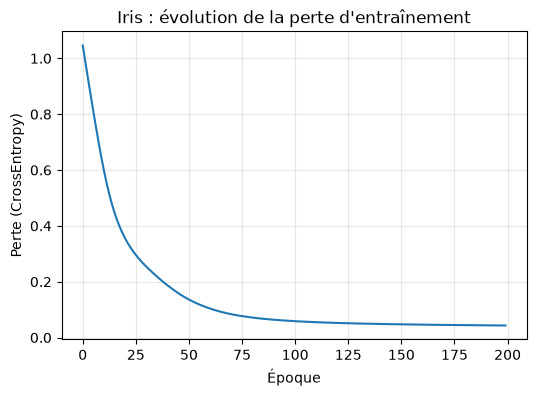

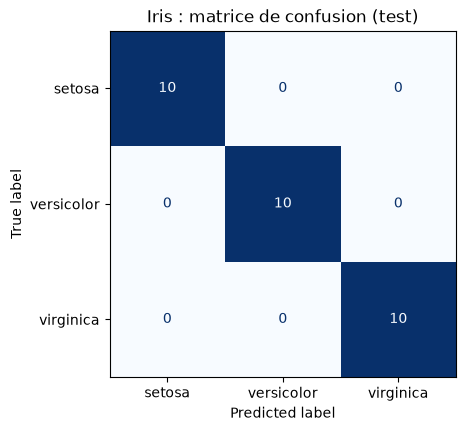

In [47]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

plt.figure(figsize=(6, 4))
plt.plot(losses)
plt.xlabel("Époque")
plt.ylabel("Perte (CrossEntropy)")
plt.title("Iris : évolution de la perte d'entraînement")
plt.grid(alpha=0.3)
plt.show()

model.eval()
with torch.no_grad():
    pred_mlp = model(X_test).argmax(dim=1)

cm = confusion_matrix(y_test.numpy(), pred_mlp.numpy())
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=iris.target_names).plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Iris : matrice de confusion (test)")
plt.show()

Accuracy réseau 4-16-3 (avec couche cachée) : 100.0%
Accuracy modèle linéaire 4-3                : 90.0%


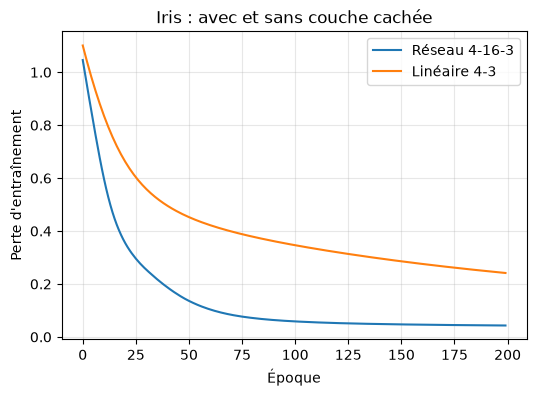

In [48]:
torch.manual_seed(42)
model_lin = nn.Linear(4, 3)
optimizer_lin = torch.optim.Adam(model_lin.parameters(), lr=0.01)
losses_lin = []

model_lin.train()
for epoch in range(200):
    optimizer_lin.zero_grad()
    loss = criterion(model_lin(X_train), y_train)
    loss.backward()
    optimizer_lin.step()
    losses_lin.append(loss.item())

model_lin.eval()
with torch.no_grad():
    pred_lin = model_lin(X_test).argmax(dim=1)

acc_mlp = (pred_mlp == y_test).float().mean().item()
acc_lin = (pred_lin == y_test).float().mean().item()
print(f"Accuracy réseau 4-16-3 (avec couche cachée) : {acc_mlp:.1%}")
print(f"Accuracy modèle linéaire 4-3                : {acc_lin:.1%}")

plt.figure(figsize=(6, 4))
plt.plot(losses, label="Réseau 4-16-3")
plt.plot(losses_lin, label="Linéaire 4-3")
plt.xlabel("Époque")
plt.ylabel("Perte d'entraînement")
plt.title("Iris : avec et sans couche cachée")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Comparaison avec le modèle sans couche cachée.** Les trois espèces d'Iris sont presque séparables par des frontières linéaires (setosa est totalement isolée ; versicolor et virginica se chevauchent légèrement). Un modèle linéaire (régression softmax) atteint donc déjà une accuracy proche de celle du réseau avec couche cachée ; la couche cachée avec ReLU apporte une capacité non linéaire qui aide surtout à la frontière versicolor/virginica. Avec seulement 30 exemples de test, une erreur de plus ou de moins vaut 3,3 points : l'écart entre les deux accuracies affichées est à interpréter avec prudence.

In [49]:

nouvelle_fleur = np.array([[5.1, 3.5, 1.4, 0.2]])
nouvelle_fleur_norm = torch.tensor(scaler.transform(nouvelle_fleur), dtype=torch.float32)  # même scaler qu'à l'entraînement

model.eval()
with torch.no_grad():
    logits_new = model(nouvelle_fleur_norm)
    probas = torch.softmax(logits_new, dim=1)[0]
    classe = logits_new.argmax(dim=1).item()

print("Espèce prédite :", iris.target_names[classe])   # setosa attendue
print({nom: round(p, 3) for nom, p in zip(iris.target_names, probas.tolist())})

Espèce prédite : setosa
{np.str_('setosa'): 1.0, np.str_('versicolor'): 0.0, np.str_('virginica'): 0.0}


###  Exercice 3  — Classification des fleurs Iris 🌸

Objectif : entraîner un réseau de neurones pour prédire l’espèce d’une fleur à partir de quatre mesures :

- longueur et largeur des sépales ;
- longueur et largeur des pétales.

Le jeu de données Iris contient 150 fleurs réparties en trois classes : setosa, versicolor et virginica.


Bibliothèques : torch, scikit-learn.

### Exercice 2 : Classifier les chiffres MNIST
Objectif : utiliser des mini-lots et évaluer un modèle sur des données de test.

Chargement des données

In [50]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=256, shuffle=False
)

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

100.0%
100.0%
100.0%
100.0%


#### Travail demandé : 
- Entraînez le modèle pendant 5 époques.
- Utilisez model.train() pendant l’entraînement.
- Évaluez-le avec model.eval() et torch.no_grad().
- Obtenez les classes prédites avec :
   - predicted_classes = outputs.argmax(dim=1)
   - Calculez mes métriques Accuracy, Recall, Precision et f1-Score sur le jeu de test.
   - Afficher la matrice de confusion
   - Affichez quelques images mal classées.
- Sauvegarder et recharger un modèle : réutiliser un réseau entraîné sans recommencer l’apprentissage.

Attention : CrossEntropyLoss attend les sorties brutes du réseau, sans Softmax, et des étiquettes entières.

#### Solution — Exercice 2 (MNIST avec un réseau dense)

Entraînement sur 5 époques avec `model.train()`.

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

epochs = 5
for epoch in range(epochs):
    model.train()
    total_loss = 0.0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()              
        outputs = model(images)            
        loss = criterion(outputs, labels)  
        loss.backward()                    
        optimizer.step()                   

        total_loss += loss.item() * images.size(0)

    print(f"Époque {epoch + 1}/{epochs} | Perte : {total_loss / len(train_dataset):.4f}")

Époque 1/5 | Perte : 0.3430
Époque 2/5 | Perte : 0.1534
Époque 3/5 | Perte : 0.1055
Époque 4/5 | Perte : 0.0798
Époque 5/5 | Perte : 0.0628


Évaluation avec `model.eval()` et `torch.no_grad()`, puis métriques. Avec 10 classes, la précision, le rappel et le F1-score sont calculés classe par classe puis moyennés (moyenne *macro*).

In [52]:
import numpy as np
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        predicted_classes = outputs.argmax(dim=1)
        all_preds.append(predicted_classes.cpu())
        all_labels.append(labels)

y_pred = torch.cat(all_preds).numpy()
y_true = torch.cat(all_labels).numpy()

print(f"Accuracy  : {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision : {precision_score(y_true, y_pred, average='macro'):.4f}  (macro)")
print(f"Recall    : {recall_score(y_true, y_pred, average='macro'):.4f}  (macro)")
print(f"F1-score  : {f1_score(y_true, y_pred, average='macro'):.4f}  (macro)")

Accuracy  : 0.9740
Precision : 0.9743  (macro)
Recall    : 0.9736  (macro)
F1-score  : 0.9738  (macro)


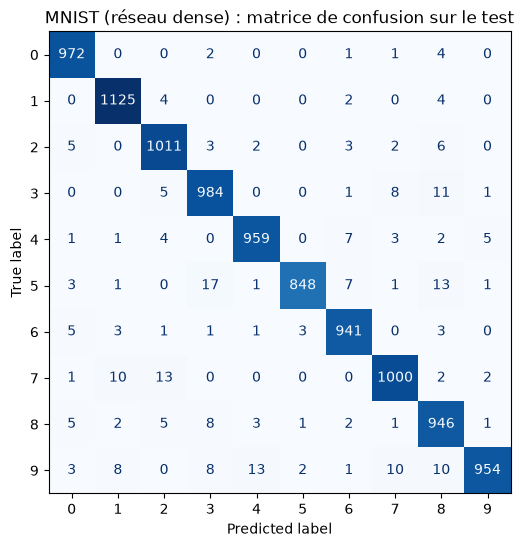

In [53]:

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=list(range(10))).plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("MNIST (réseau dense) : matrice de confusion sur le test")
plt.show()

260 images mal classées sur 10000


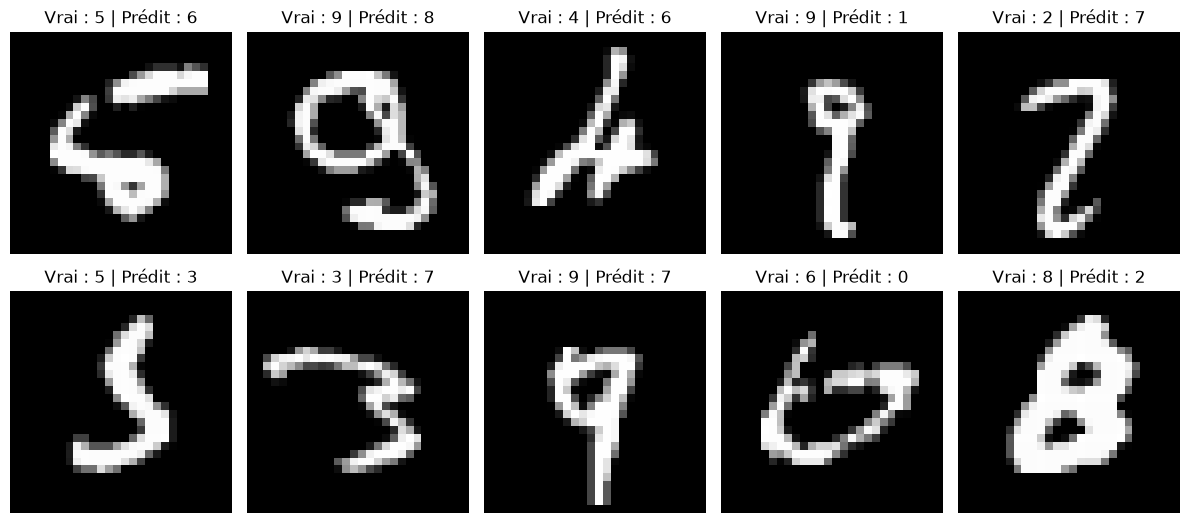

In [54]:

wrong = np.where(y_pred != y_true)[0]
print(f"{len(wrong)} images mal classées sur {len(y_true)}")

fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for ax, idx in zip(axes.ravel(), wrong[:10]):
    image, label = test_dataset[int(idx)]
    ax.imshow(image.squeeze().numpy(), cmap="gray")
    ax.set_title(f"Vrai : {label} | Prédit : {y_pred[idx]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

Sauvegarde puis rechargement : on enregistre les **paramètres** (`state_dict`), on recrée la même architecture, puis on y charge les paramètres, sans refaire l'apprentissage.

In [55]:
path = "mnist_mlp.pth"
torch.save(model.state_dict(), path)

new_model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
).to(device)
new_model.load_state_dict(torch.load(path, map_location=device, weights_only=True))
new_model.eval()

preds_new = []
with torch.no_grad():
    for images, _ in test_loader:
        preds_new.append(new_model(images.to(device)).argmax(dim=1).cpu())
preds_new = torch.cat(preds_new).numpy()

print("Prédictions identiques au modèle d'origine :", np.array_equal(preds_new, y_pred))
print(f"Accuracy du modèle rechargé : {accuracy_score(y_true, preds_new):.2%}")

Prédictions identiques au modèle d'origine : True
Accuracy du modèle rechargé : 97.40%


### Exercice 4 — Classification MNIST avec un CNN

Objectif : construire un réseau de neurones convolutif (CNN) pour reconnaître les chiffres manuscrits de 0 à 9.

MNIST contient 60 000 images d’entraînement et 10 000 images de test, en niveaux de gris, de taille 28 × 28 pixels.

**1. Chargement des données**

In [56]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil :", device)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)

test_dataset = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=256, shuffle=False
)

images, labels = next(iter(train_loader))

print("Images :", images.shape)  # [64, 1, 28, 28]
print("Labels :", labels.shape)  # [64]

Appareil : cpu
Images : torch.Size([64, 1, 28, 28])
Labels : torch.Size([64])


**Questions :**

- Que représentent les quatre dimensions du tenseur images ?
- Pourquoi mélanger les données d’entraînement avec shuffle=True ?

#### Réponses — Exercice 4, partie 1

**Que représentent les quatre dimensions du tenseur `images` ?**
`[64, 1, 28, 28]` = `[taille du lot, canaux, hauteur, largeur]` : 64 images par mini-lot, 1 canal (niveaux de gris, contre 3 pour une image RGB), 28 pixels de hauteur et 28 de largeur.

**Pourquoi mélanger les données d'entraînement avec `shuffle=True` ?**
Pour casser tout ordre éventuel du jeu de données (par exemple des chiffres rangés par classe) : sans mélange, les lots successifs seraient très corrélés et les gradients biaisés, ce qui déstabiliserait l'apprentissage. Avec `shuffle=True`, les lots sont différents à chaque époque, ce qui rend les gradients plus représentatifs de l'ensemble des données et améliore la généralisation. Le jeu de test n'a pas besoin d'être mélangé, d'où `shuffle=False`.

**2. Visualiser quelques images**

Complétez l’affichage des étiquettes :

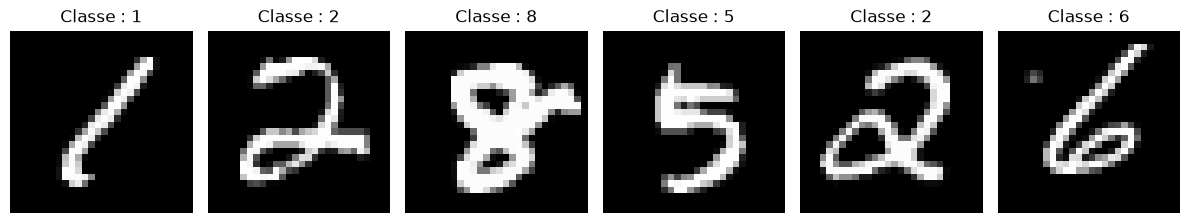

In [57]:
fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for i, ax in enumerate(axes):
    
    image = images[i, 0] * 0.3081 + 0.1307

    ax.imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Classe : {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

**3. Construire le CNN**

Implémentez cette architecture :

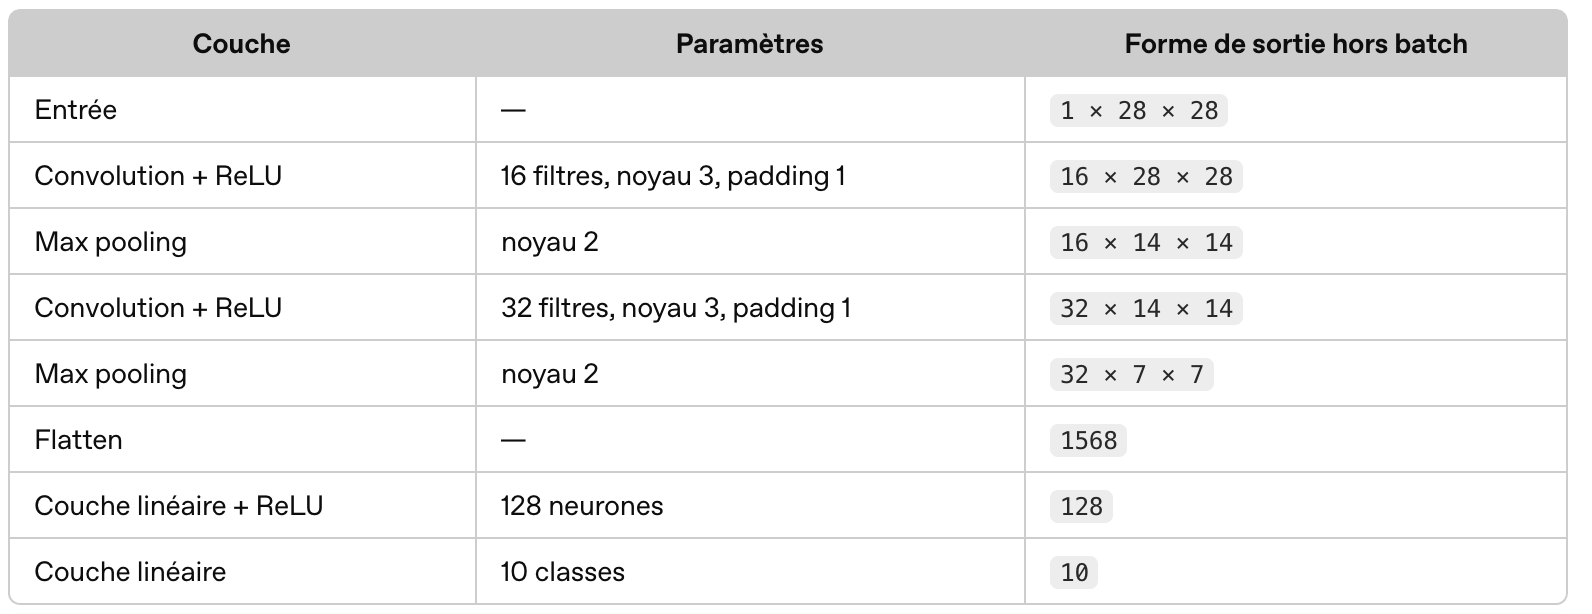

In [58]:
class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(
                in_channels=1,
                out_channels=16,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = MNISTClassifier().to(device)


with torch.no_grad():
    output = model(images.to(device))

assert output.shape == (images.size(0), 10)
print("Sortie :", output.shape)

Sortie : torch.Size([64, 10])


**Question :** pourquoi la première couche linéaire reçoit-elle 32 × 7 × 7 valeurs ?

Attention : n’ajoutez pas de Softmax au modèle. CrossEntropyLoss attend les scores bruts, appelés logits.

**Réponse.** Les convolutions avec `kernel_size=3` et `padding=1` conservent la taille spatiale. Seuls les deux `MaxPool2d(2)` la réduisent, chacun de moitié : 28 × 28 → 14 × 14 → 7 × 7. La dernière convolution produit 32 cartes de caractéristiques, donc la sortie de `features` est de forme `32 × 7 × 7`. `Flatten` l'aplatit en un vecteur de 32 × 7 × 7 = **1568 valeurs**, qui forment l'entrée de la première couche linéaire.

On n'ajoute pas de Softmax en sortie car `nn.CrossEntropyLoss` applique déjà un log-softmax en interne (de façon numériquement plus stable) et attend donc des logits.

**4. Entraîner le réseau**

In [59]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 3
loss_history = []

for epoch in range(epochs):
    model.train()
    total_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        
        optimizer.zero_grad()

       
        logits = model(images)

       
        loss = criterion(logits, labels)

        
        loss.backward()

        
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    average_loss = total_loss / len(train_dataset)
    loss_history.append(average_loss)

    print(
        f"Époque {epoch + 1}/{epochs} "
        f"| Perte : {average_loss:.4f}"
    )

Époque 1/3 | Perte : 0.1680
Époque 2/3 | Perte : 0.0482
Époque 3/3 | Perte : 0.0351


**5. Évaluer sur le jeu de test**

In [60]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)

        
        predictions = logits.argmax(dim=1)

        
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy = correct / total
print(f"Accuracy sur le test : {accuracy:.2%}")

Accuracy sur le test : 98.88%


**Indices :**

- argmax(dim=1) sélectionne une classe pour chaque image ;
(predictions == labels).sum().item() compte les prédictions correctes.

- Résultat attendu : une accuracy généralement supérieure à 97 % après quelques époques, sans garantie exacte.

**Autres questions :**

- Affichez 10 images mal classées, avec leur vraie classe et la prédiction.
- Ajoutez une couche Dropout avant la dernière couche linéaire.
- Sauvegardez les paramètres avec torch.save(model.state_dict(), "mnist_cnn.pth").

#### Solution — Exercice 4, autres questions

**1. Dix images mal classées**

112 images mal classées sur 10000


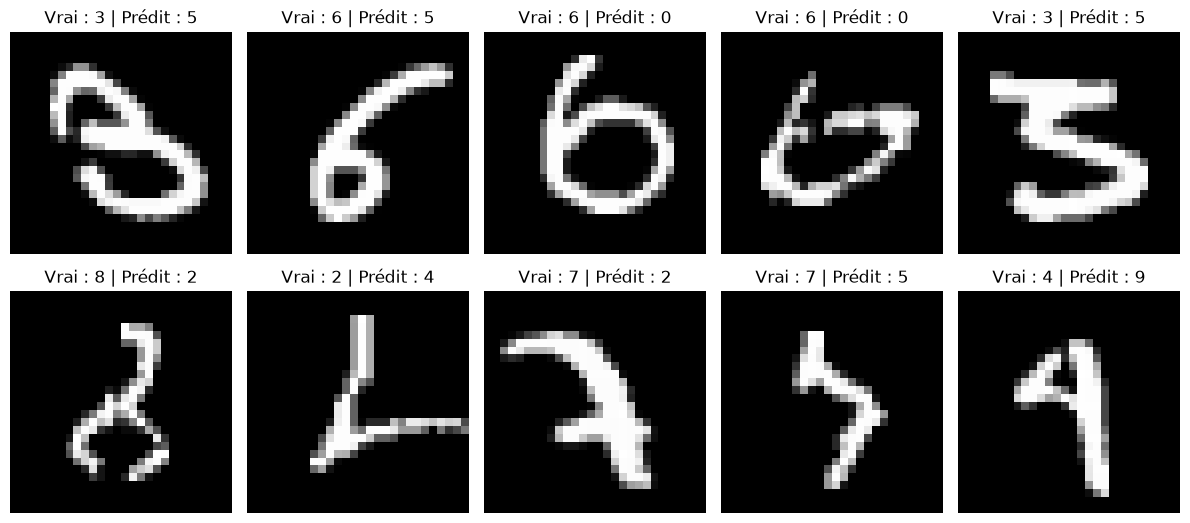

In [ ]:
import numpy as np

def predict_all(net, loader):
    """Retourne (prédictions, étiquettes) sur tout le jeu du loader."""
    net.eval()
    preds, labs = [], []
    with torch.no_grad():
        for imgs, lbls in loader:
            preds.append(net(imgs.to(device)).argmax(dim=1).cpu())
            labs.append(lbls)
    return torch.cat(preds), torch.cat(labs)

cnn_preds, cnn_labels = predict_all(model, test_loader)
wrong = (cnn_preds != cnn_labels).nonzero().squeeze(1)
print(f"{len(wrong)} images mal classées sur {len(cnn_labels)}")

fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for ax, idx in zip(axes.ravel(), wrong[:10]):
    image, label = test_dataset[int(idx)]
    image = image[0] * 0.3081 + 0.1307      
    ax.imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Vrai : {label} | Prédit : {cnn_preds[idx].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

**2. Ajouter une couche `Dropout` avant la dernière couche linéaire**

In [62]:
class MNISTClassifierDropout(MNISTClassifier):
    def __init__(self, p=0.5):
        super().__init__()
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(p),            
            nn.Linear(128, 10)
        )


torch.manual_seed(42)
model_do = MNISTClassifierDropout(p=0.5).to(device)
optimizer_do = torch.optim.Adam(model_do.parameters(), lr=0.001)

for epoch in range(3):
    model_do.train()          
    total_loss = 0.0
    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer_do.zero_grad()
        loss = criterion(model_do(imgs), lbls)
        loss.backward()
        optimizer_do.step()
        total_loss += loss.item() * imgs.size(0)
    print(f"Époque {epoch + 1}/3 | Perte : {total_loss / len(train_dataset):.4f}")

preds_do, labels_do = predict_all(model_do, test_loader)   
acc_do = (preds_do == labels_do).float().mean().item()
acc_cnn = (cnn_preds == cnn_labels).float().mean().item()
print(f"Accuracy CNN sans Dropout : {acc_cnn:.2%}")
print(f"Accuracy CNN avec Dropout : {acc_do:.2%}")

Époque 1/3 | Perte : 0.2332
Époque 2/3 | Perte : 0.0886
Époque 3/3 | Perte : 0.0653
Accuracy CNN sans Dropout : 98.88%
Accuracy CNN avec Dropout : 98.77%


Le `Dropout(p=0.5)` met à zéro au hasard la moitié des neurones de la couche cachée à chaque pas d'entraînement : le réseau ne peut plus s'appuyer sur quelques neurones précis, ce qui le **régularise** et limite le sur-apprentissage. En mode `eval()`, il est désactivé (les activations sont déjà remises à l'échelle pendant l'entraînement). Sur MNIST et seulement 3 époques, le réseau sur-apprend peu : l'écart entre les deux accuracies est en général faible, voire nul ou légèrement négatif ; l'intérêt du Dropout apparaît surtout avec des réseaux plus grands ou des entraînements plus longs.

**3. Sauvegarder les paramètres, puis les recharger**

In [63]:
torch.save(model.state_dict(), "mnist_cnn.pth")

model_loaded = MNISTClassifier().to(device)
model_loaded.load_state_dict(torch.load("mnist_cnn.pth", map_location=device, weights_only=True))
model_loaded.eval()

loaded_preds, _ = predict_all(model_loaded, test_loader)
print("Prédictions identiques au modèle d'origine :", torch.equal(loaded_preds, cnn_preds))

Prédictions identiques au modèle d'origine : True
